# Day 13: Covariance, Correlation & Linear Regression

## Learning Objectives

By the end of this notebook, I will be able to:

1. Understand covariance and its interpretation.
2. Calculate and interpret Pearson correlation.
3. Understand Spearman rank correlation.
4. Identify positive, negative, and zero correlation.
5. Create and interpret a correlation matrix.
6. Understand the difference between correlation and causation.
7. Understand Simple Linear Regression.
8. Build a Linear Regression model using Python.
9. Evaluate model performance using MAE, RMSE, and R-squared.
10. Apply these concepts to real-world business problems.

**Business Scenario:**

A company wants to understand whether increasing its advertising
spend is associated with higher sales.

We will analyze the relationship between advertising spend
and sales, and build a simple model to predict sales.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set display options
pd.set_option("display.max_columns", None)

# Set random seed for reproducibility
np.random.seed(42)

## 1. Understanding Covariance

Covariance measures how two numerical variables change together.

It helps us understand the direction of the relationship
between two variables.

### Types of Covariance

1. Positive Covariance:
   Both variables generally move in the same direction.

2. Negative Covariance:
   One variable generally increases when the other decreases.

3. Zero or Near-Zero Covariance:
   There is little or no linear co-movement between the variables.

**Important:**

- Positive covariance does not tell us how strong the relationship is.
- Negative covariance indicates an opposite direction of movement.
- Covariance depends on the units and scales of the variables.
- Covariance alone does not establish causation.

In [2]:
# Create sample datasets

positive_data = pd.DataFrame({
    "Advertising_Spend": [10, 20, 30, 40, 50],
    "Sales": [100, 200, 300, 400, 500]
})

negative_data = pd.DataFrame({
    "Product_Price": [10, 20, 30, 40, 50],
    "Product_Demand": [500, 400, 300, 200, 100]
})

print("Positive Relationship:")
display(positive_data)

print("\nNegative Relationship:")
display(negative_data)

Positive Relationship:


,Advertising_Spend,Sales
0,10,100
1,20,200
2,30,300
3,40,400
4,50,500



Negative Relationship:


,Product_Price,Product_Demand
0,10,500
1,20,400
2,30,300
3,40,200
4,50,100


In [3]:
# Calculate covariance

print("Positive Covariance:")
print(positive_data.cov())

print("\nNegative Covariance:")
print(negative_data.cov())

Positive Covariance:
                   Advertising_Spend    Sales
Advertising_Spend              250.0   2500.0
Sales                         2500.0  25000.0

Negative Covariance:
                Product_Price  Product_Demand
Product_Price           250.0         -2500.0
Product_Demand        -2500.0         25000.0


### Covariance Interpretation

- Positive covariance: Variables tend to move in the same direction.
- Negative covariance: Variables tend to move in opposite directions.
- Near-zero covariance: Little linear co-movement is observed.

**Business Example:**

If advertising spend and sales have positive covariance,
higher advertising spend tends to be associated with higher sales.

However, covariance does not tell us the strength of the relationship
in a standardized way.

For that, we use correlation.

## 2. Understanding Correlation

Correlation measures the strength and direction of the relationship
between two numerical variables.

The correlation coefficient generally ranges from -1 to +1.

| Correlation | Interpretation |
|---|---|
| +1 | Perfect positive linear relationship |
| Close to +1 | Strong positive linear relationship |
| 0 | No linear correlation |
| Close to -1 | Strong negative linear relationship |
| -1 | Perfect negative linear relationship |

### Types of Correlation

1. Positive Correlation
2. Negative Correlation
3. Zero or No Linear Correlation

**Important:**

A correlation near zero does not necessarily mean
that no relationship exists.

A strong nonlinear relationship may still have
a correlation close to zero.

In [4]:
# Create datasets for different correlation patterns

correlation_data = pd.DataFrame({
    "Positive": [10, 20, 30, 40, 50, 60],
    "Negative": [60, 50, 40, 30, 20, 10],
    "No_Linear_Pattern": [20, 50, 10, 60, 30, 40]
})

# Calculate correlation matrix
correlation_data.corr()

,Positive,Negative,No_Linear_Pattern
Positive,1.000000,-1.000000,0.257143
Negative,-1.000000,1.000000,-0.257143
No_Linear_Pattern,0.257143,-0.257143,1.000000


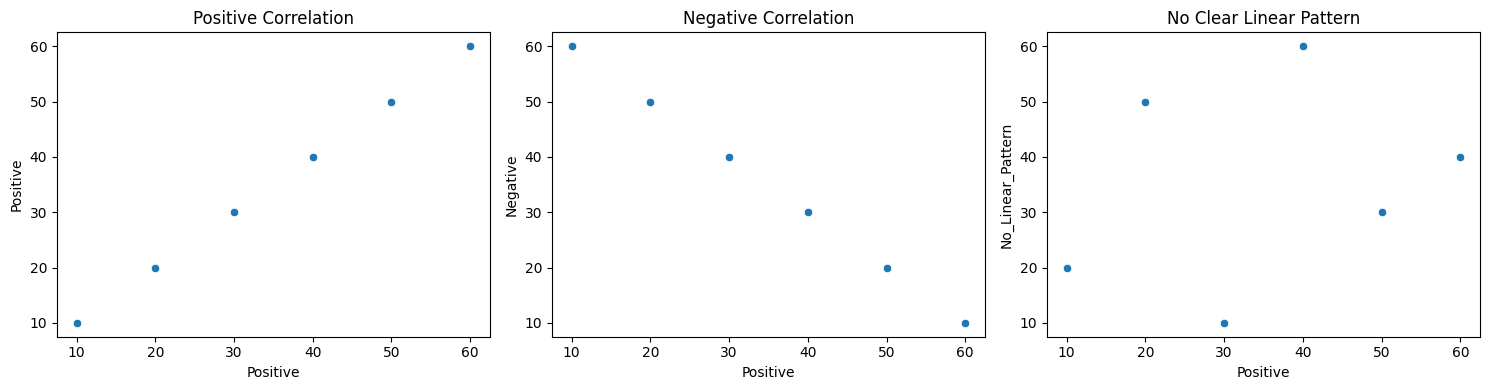

In [5]:
# Visualize different correlation patterns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(
    data=correlation_data,
    x="Positive",
    y="Positive",
    ax=axes[0]
)

axes[0].set_title("Positive Correlation")

sns.scatterplot(
    data=correlation_data,
    x="Positive",
    y="Negative",
    ax=axes[1]
)

axes[1].set_title("Negative Correlation")

sns.scatterplot(
    data=correlation_data,
    x="Positive",
    y="No_Linear_Pattern",
    ax=axes[2]
)

axes[2].set_title("No Clear Linear Pattern")

plt.tight_layout()
plt.show()

## 3. Pearson Correlation

Pearson correlation measures the strength and direction
of a linear relationship between two numerical variables.

Its coefficient is represented by r.

### Interpretation

- r = +1: Perfect positive linear relationship.
- r = -1: Perfect negative linear relationship.
- r = 0: No linear correlation.

### Important Assumptions and Considerations

- Variables should be numerical.
- The relationship should be approximately linear
  when interpreting Pearson correlation.
- Outliers can strongly affect the coefficient.
- For formal statistical inference, consider the assumptions
  behind the Pearson correlation test.

**Business Example:**

We can use Pearson correlation to examine whether
advertising spend and sales move together linearly.

In [6]:
# Create a realistic sample business dataset

n = 100

advertising_spend = np.random.uniform(10, 100, n)

sales = (
    200
    + 8 * advertising_spend
    + np.random.normal(0, 80, n)
)

marketing_df = pd.DataFrame({
    "Advertising_Spend": advertising_spend,
    "Sales": sales
})

marketing_df.head()

,Advertising_Spend,Sales
0,43.708611,556.632651
1,95.564288,940.593713
2,75.879455,814.376500
3,63.879264,552.028595
4,24.041678,374.759670


In [7]:
# Explore the dataset

print("Dataset Shape:")
print(marketing_df.shape)

print("\nDataset Information:")
marketing_df.info()

print("\nStatistical Summary:")
display(marketing_df.describe())

Dataset Shape:
(100, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Advertising_Spend  100 non-null    float64
 1   Sales              100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB

Statistical Summary:


,Advertising_Spend,Sales
count,100.000000,100.000000
mean,52.316267,618.443706
std,26.774047,215.696344
min,10.496991,239.009709
25%,27.388068,430.387687
50%,51.772821,586.250762
75%,75.718281,808.344818
max,98.819824,1053.104424


In [8]:
# Calculate Pearson correlation

pearson_corr, pearson_p_value = pearsonr(
    marketing_df["Advertising_Spend"],
    marketing_df["Sales"]
)

print("Pearson Correlation:", round(pearson_corr, 4))
print("P-value:", round(pearson_p_value, 4))

Pearson Correlation: 0.9423
P-value: 0.0


### Interpreting Pearson Correlation

The correlation coefficient tells us the direction
and strength of the linear relationship.

The p-value helps us assess statistical evidence
against the null hypothesis of zero population correlation.

At a 5% significance level:

- If p-value < 0.05, reject the null hypothesis.
- If p-value >= 0.05, do not reject the null hypothesis.

**Remember:**

Statistical significance does not automatically mean
that a relationship is practically important.

Also, correlation does not prove causation.

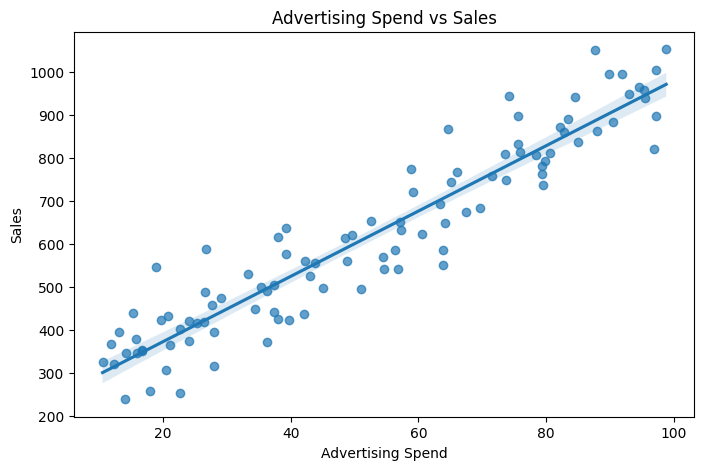

In [9]:
# Visualize the relationship between advertising spend and sales

plt.figure(figsize=(8, 5))

sns.regplot(
    data=marketing_df,
    x="Advertising_Spend",
    y="Sales",
    scatter_kws={"alpha": 0.7}
)

plt.title("Advertising Spend vs Sales")
plt.xlabel("Advertising Spend")
plt.ylabel("Sales")

plt.show()

## 4. Spearman Rank Correlation

Spearman correlation measures the strength and direction
of a monotonic relationship between two variables.

A monotonic relationship means that as one variable increases,
the other generally tends to increase or decrease.

Unlike Pearson correlation, Spearman correlation uses
the ranks of observations.

### When to Use Spearman Correlation?

- When the relationship is monotonic but not necessarily linear.
- When data contains influential outliers.
- When variables are ordinal or rank-based.
- When Pearson's linear relationship assumption is not suitable.

**Note:**

Spearman correlation is not automatically immune to outliers.
It can still be affected by unusual observations and tied ranks.

In [10]:
# Create a monotonic but nonlinear dataset

monotonic_data = pd.DataFrame({
    "Experience": np.arange(1, 11)
})

monotonic_data["Salary"] = (
    25000
    + 15000 * np.sqrt(monotonic_data["Experience"])
)

display(monotonic_data)

# Calculate Pearson and Spearman correlation

pearson_value, _ = pearsonr(
    monotonic_data["Experience"],
    monotonic_data["Salary"]
)

spearman_value, _ = spearmanr(
    monotonic_data["Experience"],
    monotonic_data["Salary"]
)

print("Pearson Correlation:", round(pearson_value, 4))
print("Spearman Correlation:", round(spearman_value, 4))

,Experience,Salary
0,1,40000.000000
1,2,46213.203436
2,3,50980.762114
3,4,55000.000000
4,5,58541.019662
5,6,61742.346142
6,7,64686.269666
7,8,67426.406871
8,9,70000.000000
9,10,72434.164903


Pearson Correlation: 0.9892
Spearman Correlation: 1.0


## 5. Correlation Matrix and Heatmap

A correlation matrix shows the pairwise correlation
between numerical variables in a dataset.

It is useful when analyzing multiple business variables.

### Business Applications

- Finding variables related to sales.
- Understanding customer behavior.
- Exploring relationships between marketing metrics.
- Identifying highly correlated features before modeling.

**Important:**

High correlation between independent variables
may create multicollinearity in regression models.

Correlation analysis is useful for exploration,
but it should not be the only basis for removing features.

In [11]:
# Create additional business variables

marketing_df["Website_Visitors"] = (
    500 + marketing_df["Advertising_Spend"] * 12
    + np.random.normal(0, 50, n)
)

marketing_df["Orders"] = (
    20 + marketing_df["Sales"] / 100
    + np.random.normal(0, 5, n)
)

marketing_df["Customer_Satisfaction"] = np.random.uniform(
    3, 5, n
)

# Calculate correlation matrix

correlation_matrix = marketing_df.corr(numeric_only=True)

display(correlation_matrix)

,Advertising_Spend,Sales,Website_Visitors,Orders,Customer_Satisfaction
Advertising_Spend,1.000000,0.942298,0.985742,0.473019,0.058165
Sales,0.942298,1.000000,0.927603,0.515569,0.004328
Website_Visitors,0.985742,0.927603,1.000000,0.451485,0.032137
Orders,0.473019,0.515569,0.451485,1.000000,0.025760
Customer_Satisfaction,0.058165,0.004328,0.032137,0.025760,1.000000


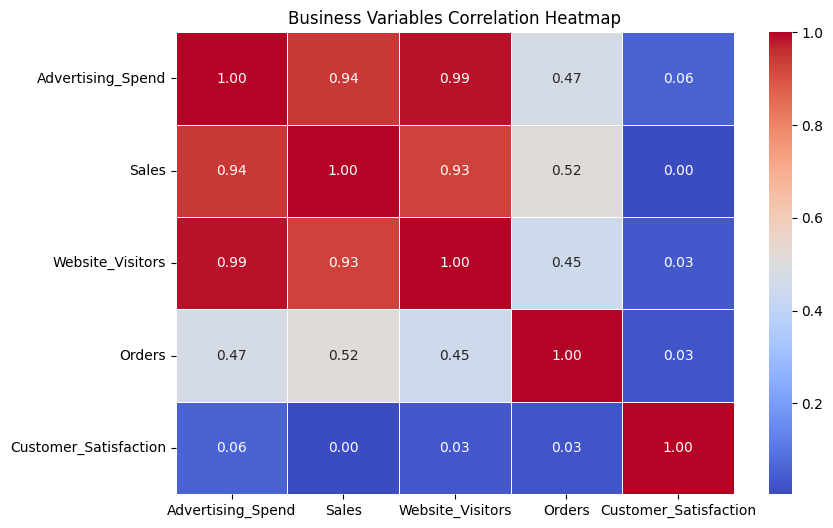

In [12]:
# Create correlation heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Business Variables Correlation Heatmap")
plt.show()

## 6. Correlation vs Causation

Correlation means two variables are associated.

Causation means a change in one variable directly
produces a change in another variable.

### Example

Ice cream sales and cold drink sales may increase together.

They are correlated, but buying ice cream does not necessarily
cause people to buy cold drinks.

A third factor, such as hot weather, may influence both.

### Why Correlation Does Not Prove Causation

1. Confounding variables may affect both variables.
2. Reverse causality may exist.
3. The relationship may occur by coincidence.
4. Other hidden factors may explain the association.

**Business Lesson:**

Before making business decisions based on correlation,
investigate the underlying reason for the relationship.

Experiments, such as properly designed A/B tests,
can help evaluate causal effects.

## 7. Simple Linear Regression

Linear Regression is a supervised machine learning
and statistical modeling technique.

It models the relationship between an independent variable
and a dependent variable using a linear equation.

### Equation

Sales = Intercept + (Slope × Advertising Spend)

Or:

Y = b0 + b1X

Where:

- Y = Dependent variable (target)
- X = Independent variable (feature)
- b0 = Intercept
- b1 = Slope (coefficient)

### Interpretation

Intercept:
The predicted value of Y when X is zero.

Slope:
The expected change in Y for a one-unit increase in X,
according to the fitted linear model.

**Business Example:**

We want to predict sales using advertising spend.

In [13]:
# Select independent and dependent variables

X = marketing_df[["Advertising_Spend"]]
y = marketing_df["Sales"]

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (80, 1)
Testing Data Shape: (20, 1)


In [14]:
# Build and train the Linear Regression model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Display model parameters

print("Intercept:", round(linear_model.intercept_, 2))

print("Coefficient:", round(linear_model.coef_[0], 2))

Intercept: 215.0
Coefficient: 7.64


### Interpreting the Regression Model

The coefficient represents the expected change
in predicted sales for a one-unit increase
in advertising spend.

For example, if the coefficient is approximately 8:

A one-unit increase in advertising spend is associated
with an estimated 8-unit increase in predicted sales.

The intercept represents predicted sales
when advertising spend is zero.

**Important:**

The intercept may not have a meaningful business interpretation
if zero advertising spend is outside the observed data range.

Regression estimates an association in this example.
It does not prove that increasing advertising spend
will independently cause sales to increase.

In [15]:
# Make predictions on testing data

y_pred = linear_model.predict(X_test)

# Compare actual and predicted values

comparison_df = pd.DataFrame({
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred
})

display(comparison_df.head(10))

,Actual_Sales,Predicted_Sales
0,378.286301,335.154333
1,883.997640,906.977449
2,737.060177,822.653899
3,684.265048,747.176702
4,529.604143,469.445689
5,621.033583,594.210350
6,490.753223,492.396969
7,1050.696428,885.154822
8,368.053005,305.592970
9,556.632651,549.076137


## 8. Evaluating Regression Model Performance

We will use three common regression evaluation metrics.

### 1. MAE — Mean Absolute Error

MAE measures the average absolute difference
between actual and predicted values.

Lower MAE generally indicates better predictions.

### 2. RMSE — Root Mean Squared Error

RMSE measures the square root of the average
squared prediction errors.

It penalizes larger errors more strongly than MAE.

Lower RMSE generally indicates better predictions.

### 3. R-squared

R-squared measures how much variation in the target variable
is explained by the model relative to a baseline
that predicts the target mean.

A higher value can indicate a better fit,
but it does not guarantee good predictions on new data.

R-squared can also be negative on test data
when the model performs worse than the baseline.

In [16]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))

Model Evaluation
----------------
MAE: 47.31
RMSE: 64.68
R-squared: 0.912


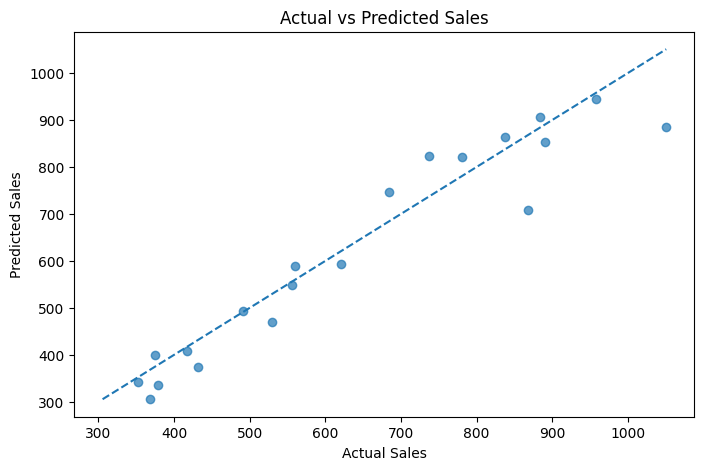

In [17]:
# Visualize actual vs predicted sales

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

## 9. Residual Analysis

A residual is the difference between the actual
and predicted value.

Residual = Actual Value - Predicted Value

Residual analysis helps us understand
where the model makes prediction errors.

### What Should We Look For?

- Residuals should generally be centered around zero.
- A clear pattern may indicate that the linear model
  is not capturing the relationship properly.
- Increasing or decreasing spread may indicate
  non-constant error variance.
- Extreme residuals may indicate unusual observations.

A residual plot is an important diagnostic tool,
but it does not prove that every regression assumption is satisfied.

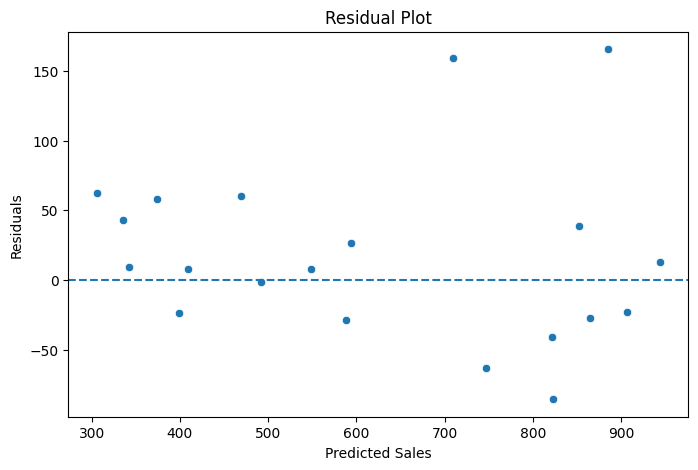

In [18]:
# Calculate residuals

residuals = y_test - y_pred

# Plot residuals against predicted values

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

## 10. Predict Sales for New Advertising Spend

After training and evaluating the model,
we can use it to predict sales for new observations.

**Business Scenario:**

The marketing team wants an estimated sales value
for a planned advertising spend of 75 units.

Remember that this prediction is based on the relationship
learned from historical sample data.

In [19]:
# Predict sales for a new advertising spend

new_data = pd.DataFrame({
    "Advertising_Spend": [75]
})

predicted_sales = linear_model.predict(new_data)

print(
    "Predicted Sales:",
    round(predicted_sales[0], 2)
)

Predicted Sales: 788.24


## 11. Business Applications

### Data Analyst

- Analyze relationships between business KPIs.
- Identify factors associated with revenue.
- Explore customer behavior patterns.
- Prepare correlation reports for business teams.

### Marketing Analyst

- Analyze advertising spend and sales relationships.
- Study website traffic and conversion metrics.
- Evaluate campaign performance.
- Support marketing budget decisions.

### Business Analyst

- Identify relationships between operational metrics.
- Analyze cost and revenue trends.
- Support data-driven business decisions.

### Data Scientist

- Build predictive regression models.
- Study feature relationships.
- Evaluate model assumptions and performance.
- Extend analysis to multiple regression and other models.

## 12. Quick Revision

| Concept | Meaning |
|---|---|
| Covariance | Direction of joint variation |
| Correlation | Strength and direction of association |
| Pearson | Measures linear correlation |
| Spearman | Measures monotonic rank correlation |
| Correlation Matrix | Pairwise correlations between variables |
| Linear Regression | Models a linear relationship |
| Intercept | Predicted Y when X is zero |
| Coefficient | Expected change in predicted Y for one-unit increase in X |
| MAE | Average absolute prediction error |
| RMSE | Square root of average squared prediction error |
| R-squared | Explained variation relative to a mean baseline |
| Residual | Actual value minus predicted value |

### Important Reminders

1. Correlation does not prove causation.
2. Pearson correlation measures linear association.
3. Spearman correlation measures monotonic association.
4. Outliers can affect correlation.
5. Regression models should be evaluated on unseen data.
6. A high R-squared does not guarantee a good model.
7. Residual analysis helps evaluate model behavior.

## 13. Interview Questions and Answers

### Q1. What is covariance?

Covariance measures how two variables change together.
Positive covariance indicates movement in the same direction,
while negative covariance indicates movement in opposite directions.

### Q2. What is correlation?

Correlation measures the strength and direction
of the relationship between two variables.

### Q3. What is the range of the correlation coefficient?

It ranges from -1 to +1.

### Q4. What is the difference between Pearson and Spearman correlation?

Pearson measures linear relationships,
while Spearman measures monotonic relationships using ranks.

### Q5. Does zero correlation mean there is no relationship?

No. It means there is no linear correlation.
A nonlinear relationship may still exist.

### Q6. What is the difference between correlation and causation?

Correlation indicates association.
Causation means one variable produces a change in another.

### Q7. What is Linear Regression?

Linear Regression is a technique that models
the relationship between a dependent variable
and one or more independent variables.

### Q8. What is the difference between dependent and independent variables?

The dependent variable is the target we want to explain or predict.
Independent variables are the inputs used by the model.

### Q9. What does the coefficient mean in Linear Regression?

It represents the expected change in the predicted target
for a one-unit increase in the independent variable,
holding other variables constant in a multiple regression model.

### Q10. What is an intercept?

It is the predicted value of the dependent variable
when all independent variables are zero.

### Q11. What is R-squared?

It measures the proportion of target variation
explained by the model relative to a mean baseline.

### Q12. What is the difference between MAE and RMSE?

MAE uses absolute errors.
RMSE squares errors before averaging and taking the square root,
so it penalizes larger errors more heavily.

### Q13. What is a residual?

A residual is the difference between an actual value
and its predicted value.

### Q14. Why do we split data into training and testing sets?

Training data is used to fit the model.
Testing data helps evaluate how well it performs
on observations not used during training.

### Q15. Can correlation be used to select features?

Yes, it can help explore relationships between variables.
However, feature selection should also consider business context,
nonlinear relationships, multicollinearity, and model performance.

## 14. Practice Tasks

Try these tasks independently.

### Task 1 — Covariance

Create a small dataset containing:
- Monthly Advertising Spend
- Monthly Sales

Calculate covariance and interpret its direction.

### Task 2 — Pearson Correlation

Calculate Pearson correlation between advertising spend
and sales in the marketing dataset.

Explain the result in simple business language.

### Task 3 — Spearman Correlation

Calculate Spearman correlation between experience
and salary in the monotonic dataset.

Compare it with Pearson correlation.

### Task 4 — Correlation Heatmap

Create a heatmap using all numerical columns
in the marketing dataset.

Identify the two variables with the strongest
positive correlation.

### Task 5 — Linear Regression

Build a Linear Regression model using:
- Independent variable: Advertising Spend
- Dependent variable: Sales

Evaluate it using MAE, RMSE, and R-squared.

### Task 6 — Business Interpretation

Explain the meaning of:
- Intercept
- Regression coefficient
- R-squared
- MAE

Use simple business language.

### Task 7 — Critical Thinking

If advertising spend and sales have a strong positive correlation,
can we conclude that increasing advertising spend
will always increase sales?

Explain why or why not.

## 15. Final Conclusion

In this notebook, I learned:

- Covariance and how to interpret its direction.
- Pearson and Spearman correlation.
- Correlation matrices and heatmaps.
- The difference between correlation and causation.
- Simple Linear Regression.
- Training and testing a regression model.
- Model evaluation using MAE, RMSE, and R-squared.
- Residual analysis and business interpretation.

**Key Takeaway:**

Correlation helps us understand relationships,
while Linear Regression helps us model relationships
and make predictions.

Both are important tools for Data Analysts
and Data Scientists.

**Next Topic:**

Day 14 — A/B Testing and Business Statistics.